# Inspect Align EEG data

In [51]:
# import scipy.io as sio
# import numpy as np
# import os
# import pandas as pd

# path = r"C:\Users\pipo\Datasets-Docs\Multimodal Dataset for Mixed Emotion Recognition\Aligned_data_001"
# files = os.listdir(path)


# for i in files:
#     print(f"Processing subject: {i}")
#     subject_id = i
#     path_load = f"{path}\\{subject_id}"
#     data = sio.loadmat(path_load + r"\datas.mat")
    
#     path_behave_VAD = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Arousal_Valence.csv"
#     path_behave_Emotion = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Emotions.csv"
#     path_behave_PANAS = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Panas.csv"
    
#     behave_VAD = pd.read_csv(path_behave_VAD, header=None).to_numpy()
#     behave_Emotion = pd.read_csv(path_behave_Emotion, header=None).to_numpy()
#     behave_PANAS = pd.read_csv(path_behave_PANAS, header=None).to_numpy()
    
#     if behave_VAD.shape != (32,4) or behave_Emotion.shape != (32,3) or behave_PANAS.shape != (32,11):
#         print(f"behave_data ERROR: "
#             f"subject: {subject_id}: "
#             f"VAD shape: {behave_VAD.shape}, "
#             f"Emotion shape: {behave_Emotion.shape}, "
#             f"PANAS shape: {behave_PANAS.shape}")

#     eeg = data["eeg_datas"]

#     fs_eeg = 300  # EEG sampling rate

#     # According to the published aligned-data format
#     video_ids = eeg[-2, :].astype(int)

#     total_samples = 0
#     count = 0

#     for vid in range(32):
#         mask = video_ids == vid
#         n_samples = np.sum(mask)
#         duration = n_samples / fs_eeg

#         total_samples += n_samples
        
#         if n_samples < 5000:
#             print(
#                 f"datas ERROR: "
#                 f"subject: {subject_id}: "
#                 f"Video ID {vid:02d}: "
#                 f"{duration:.2f} seconds, "
#                 f"{n_samples} EEG samples"
#             )
#             count += 1
#     # print(count)
#     # break
    

**I will exclude s2 and s35 becuase data lose**

# Prepare the Data

In [ ]:
import scipy.io as sio
import numpy as np
import os
import pandas as pd

# EEG, GSR, and PPG data loading
subject_id = "1"
path_data = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Aligned_data_001\\{subject_id}"
data = sio.loadmat(path_data + r"\datas.mat")

# Behavioral data loading
path_behave_VAD = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Arousal_Valence.csv"
path_behave_Emotion = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Emotions.csv"
path_behave_PANAS = f"C:\\Users\\pipo\\Datasets-Docs\\Multimodal Dataset for Mixed Emotion Recognition\\Raw_data_001\\{subject_id}\\{subject_id}\\Panas.csv"

eeg = data["eeg_datas"]
gsr = data["gsr_datas"]
ppg = data["ppg_datas"]

fs_eeg = 300
fs_gsr = 4
fs_ppg = 100

eeg_trials = []
gsr_trials = []
ppg_trials = []

behave_VAD = pd.read_csv(path_behave_VAD, header=None).to_numpy()
behave_Emotion = pd.read_csv(path_behave_Emotion, header=None).to_numpy()
behave_PANAS = pd.read_csv(path_behave_PANAS, header=None).to_numpy()

behave_VAD_trials = [] # Valence, Arousal, Dominance values for each trial
behave_Emotion_trials = [] # amusement and disgust values for each trial
behave_PANAS_trials = [] # PANAS values for each trial

for vid in range(32):
    # EEG: 18 channels
    eeg_trial = eeg[:18, eeg[-2, :] == vid]

    # GSR: 1 channel
    gsr_trial = gsr[:1, gsr[-2, :] == vid]

    # PPG: 1 channel
    ppg_trial = ppg[:1, ppg[-2, :] == vid]
    
    # Map 1st column of behavioral data to the corresponding video ID
    VAD_trial = behave_VAD[behave_VAD[:, 0] == vid, 1:]
    Emotion_trial = behave_Emotion[behave_Emotion[:, 0] == vid, 1:]
    PANAS_trial = behave_PANAS[behave_PANAS[:, 0] == vid, 1:]

    eeg_trials.append(eeg_trial)
    gsr_trials.append(gsr_trial)
    ppg_trials.append(ppg_trial)
    
    behave_VAD_trials.append(VAD_trial)
    behave_Emotion_trials.append(Emotion_trial)
    behave_PANAS_trials.append(PANAS_trial)

# Variable-length trials are preserved in these lists.
print("Total trials:", len(eeg_trials))
print("Trial 1 EEG:", eeg_trials[0].shape)
print("Trial 1 GSR:", gsr_trials[0].shape)
print("Trial 1 PPG:", ppg_trials[0].shape)
print("VAD:", behave_VAD_trials[0])
print("Emotion:", behave_Emotion_trials[0])
print("PANAS:", behave_PANAS_trials[0])

Total trials: 32
Trial 1 EEG: (18, 6300)
Trial 1 GSR: (1, 84)
Trial 1 PPG: (1, 2100)
VAD: [[6 7 9]]
Emotion: [[4 1]]
PANAS: [[3 1 3 3 2 1 1 1 1 1]]


In [53]:
behave_VAD_trials

[array([[6, 7, 9]]),
 array([[5, 4, 7]]),
 array([[5, 4, 6]]),
 array([[6, 7, 9]]),
 array([[4, 6, 9]]),
 array([[9, 9, 8]]),
 array([[7, 7, 8]]),
 array([[7, 7, 9]]),
 array([[7, 3, 8]]),
 array([[7, 2, 7]]),
 array([[7, 2, 6]]),
 array([[7, 3, 6]]),
 array([[7, 3, 6]]),
 array([[8, 2, 5]]),
 array([[6, 3, 6]]),
 array([[4, 3, 7]]),
 array([[7, 5, 8]]),
 array([[5, 2, 9]]),
 array([[4, 4, 8]]),
 array([[5, 3, 6]]),
 array([[5, 4, 7]]),
 array([[4, 4, 7]]),
 array([[6, 5, 7]]),
 array([[7, 3, 7]]),
 array([[7, 3, 7]]),
 array([[5, 3, 7]]),
 array([[7, 3, 6]]),
 array([[5, 3, 7]]),
 array([[7, 2, 6]]),
 array([[5, 3, 7]]),
 array([[6, 3, 7]]),
 array([[6, 3, 7]])]

# Extract EEG, GSR, and PPG features

Modality	Window length	Step	Extracted features
- EEG	4 s	1 s	Log bandpower in 5 frequency bands × 18 channels = 90
- GSR	5 s	1 s	Mean, standard deviation, slope
- PPG	8 s	1 s	Estimated pulse rate, signal standard deviation

In [54]:
from scipy.signal import welch

# =========================
# SETTINGS
# =========================
eeg_window = 4  # seconds
gsr_window = 5
ppg_window = 8

step = 0.5  # second

freq_bands = {
    "Delta": (1, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Beta":  (13, 30),
    "Gamma": (30, 50)
}

# =========================
# FEATURE STORAGE
# =========================
eeg_features = []
gsr_features = []
ppg_features = []

trial_lengths = []
feature_times = []
trial_ids = []

# =========================
# EXTRACT FEATURES
# =========================
for vid in range(32):

    eeg_trial = eeg_trials[vid]
    gsr_trial = gsr_trials[vid]
    ppg_trial = ppg_trials[vid]

    # Common duration for this trial
    duration = int(min(
        eeg_trial.shape[1] / fs_eeg,
        gsr_trial.shape[1] / fs_gsr,
        ppg_trial.shape[1] / fs_ppg
    ))

    # Align the ends of the three recordings
    eeg_trial = eeg_trial[:, -duration * fs_eeg:]
    gsr_trial = gsr_trial[:, -duration * fs_gsr:]
    ppg_trial = ppg_trial[:, -duration * fs_ppg:]

    eeg_fea_trial = []
    gsr_fea_trial = []
    ppg_fea_trial = []

    # First valid time point = 8 seconds
    
    # for t in range(
    #     max(eeg_window, gsr_window, ppg_window),
    #     duration + 1,step):
    for t in np.arange(
        max(eeg_window, gsr_window, ppg_window),
        duration + step / 2, step):

        # =========================
        # EEG FEATURES
        # =========================
        
        # eeg_seg = eeg_trial[
        #     :,
        #     (t - eeg_window) * fs_eeg : t * fs_eeg
        # ]
        eeg_seg = eeg_trial[
            :,
            int(round((t - eeg_window) * fs_eeg)):
            int(round(t * fs_eeg))
        ]

        freqs, psd = welch(
            eeg_seg,
            fs=fs_eeg,
            nperseg=eeg_seg.shape[1],
            axis=1
        )

        eeg_fea = []

        for band, (low, high) in freq_bands.items():

            mask = (freqs >= low) & (freqs < high)

            band_power = (
                psd[:, mask].sum(axis=1)
                * (freqs[1] - freqs[0])
            )

            log_power = np.log10(band_power + 1e-18)

            eeg_fea.extend(log_power)

        eeg_fea_trial.append(eeg_fea)

        # =========================
        # GSR FEATURES
        # =========================
        
        # gsr_seg = gsr_trial[
        #     0,
        #     (t - gsr_window) * fs_gsr : t * fs_gsr
        # ]
        
        gsr_seg = gsr_trial[
            0,
            int(round((t - gsr_window) * fs_gsr)):
            int(round(t * fs_gsr))
        ]

        gsr_mean = np.mean(gsr_seg)
        gsr_std = np.std(gsr_seg)

        gsr_slope = (
            (gsr_seg[-1] - gsr_seg[0])
            / ((len(gsr_seg) - 1) / fs_gsr)
        )

        gsr_fea_trial.append([
            gsr_mean,
            gsr_std,
            gsr_slope
        ])

        # =========================
        # PPG FEATURES
        # =========================
        # ppg_seg = ppg_trial[
        #     0,
        #     (t - ppg_window) * fs_ppg : t * fs_ppg
        # ]
        ppg_seg = ppg_trial[
            0,
            int(round((t - ppg_window) * fs_ppg)):
            int(round(t * fs_ppg))
        ]

        ppg_std = np.std(ppg_seg)

        # Estimate pulse rate from spectral peak
        f_ppg, psd_ppg = welch(
            ppg_seg,
            fs=fs_ppg,
            nperseg=len(ppg_seg),
            nfft=4096
        )

        # Approximate 42–180 beats/min
        mask = (f_ppg >= 0.7) & (f_ppg <= 3.0)

        peak_freq = f_ppg[mask][
            np.argmax(psd_ppg[mask])
        ]

        pulse_rate = peak_freq * 60

        ppg_fea_trial.append([
            pulse_rate,
            ppg_std
        ])

    # =========================
    # STORE TRIAL FEATURES
    # =========================
    eeg_features.append(np.array(eeg_fea_trial))
    gsr_features.append(np.array(gsr_fea_trial))
    ppg_features.append(np.array(ppg_fea_trial))

    trial_lengths.append(len(eeg_fea_trial))

    # feature_times.append(
    #     np.arange(
    #         max(eeg_window, gsr_window, ppg_window),
    #         duration + 1,
    #         step
    #     )
    # )
    feature_times.append(
        np.arange(
            max(eeg_window, gsr_window, ppg_window),
            duration + step / 2,
            step
        )
    )

    trial_ids.append(
        np.full(len(eeg_fea_trial), vid)
    )

print("Feature extraction completed!")

Feature extraction completed!


# Align features and concatenate trials

Now every time point has:
- 90 EEG features
- 3 GSR features
- 2 PPG features

In [55]:
EEG = np.concatenate(eeg_features, axis=0)
GSR = np.concatenate(gsr_features, axis=0)
PPG = np.concatenate(ppg_features, axis=0)

# GLHMM inputs
Y = EEG
X = np.concatenate([GSR, PPG], axis=1)

# Keep video IDs
video_ids_features = np.concatenate(trial_ids)

print("EEG (Y):", Y.shape)
print("Physiology (X):", X.shape)

EEG (Y): (1270, 90)
Physiology (X): (1270, 5)


In [56]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Y: EEG features (651, 90)
# X: GSR + PPG features (651, 5)

# Check for invalid values
assert np.isfinite(Y).all(), "EEG contains NaN or Inf"
assert np.isfinite(X).all(), "GSR/PPG contains NaN or Inf"

# Initialize scalers
scaler_eeg = StandardScaler()
scaler_physio = StandardScaler()

# Standardize each feature across all trials
Y_std = scaler_eeg.fit_transform(Y)
X_std = scaler_physio.fit_transform(X)

print("EEG shape:", Y_std.shape)
print("Physiology shape:", X_std.shape)

EEG shape: (1270, 90)
Physiology shape: (1270, 5)


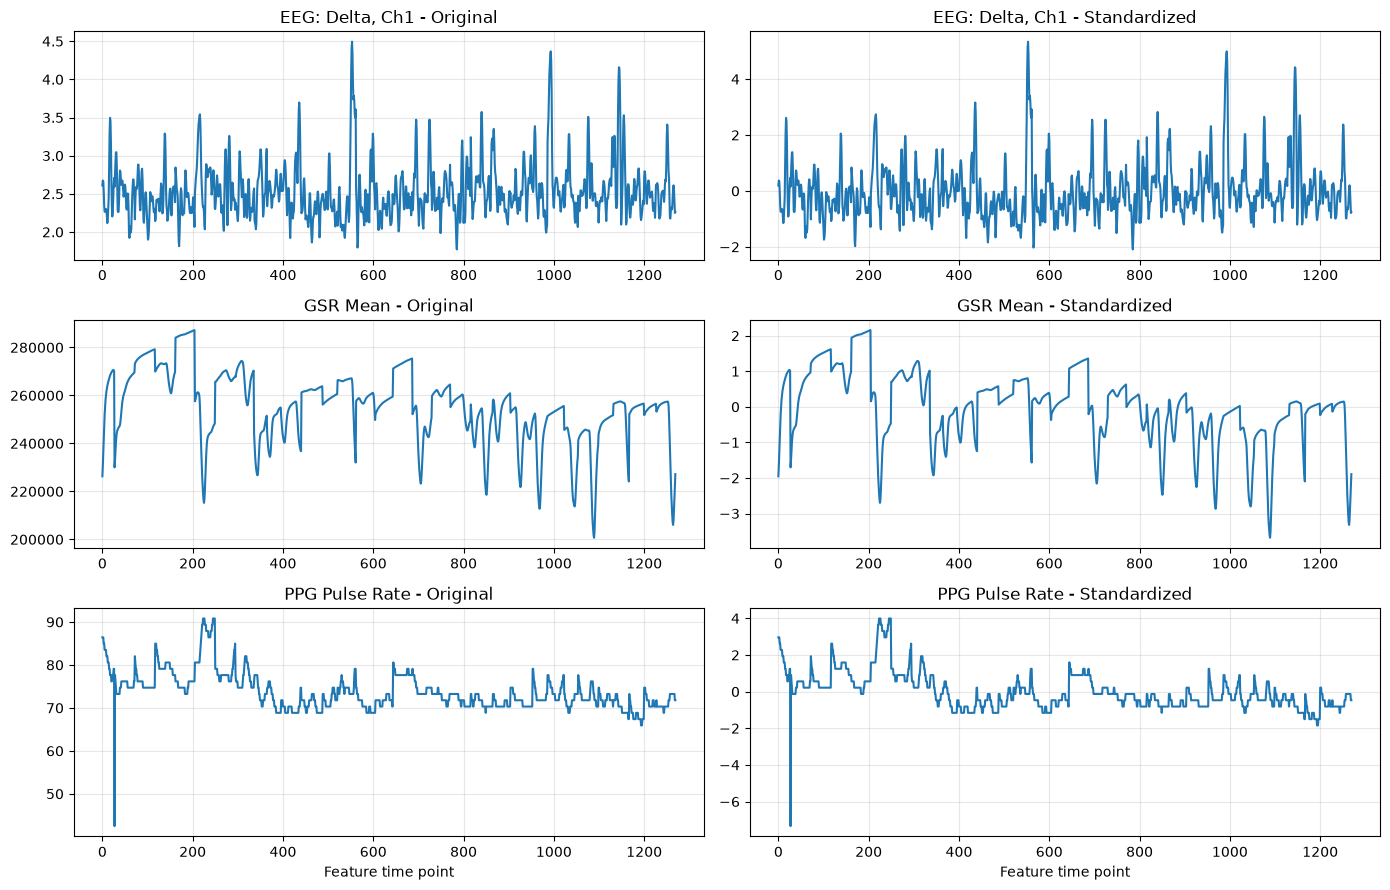

In [57]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 9))

features = [
    (Y[:, 0], Y_std[:, 0], "EEG: Delta, Ch1"),
    (X[:, 0], X_std[:, 0], "GSR Mean"),
    (X[:, 3], X_std[:, 3], "PPG Pulse Rate")
]

for i, (original, standardized, name) in enumerate(features):

    axes[i, 0].plot(original)
    axes[i, 0].set_title(f"{name} - Original")
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(standardized)
    axes[i, 1].set_title(f"{name} - Standardized")
    axes[i, 1].grid(alpha=0.3)

axes[-1, 0].set_xlabel("Feature time point")
axes[-1, 1].set_xlabel("Feature time point")

plt.tight_layout()
plt.show()

# For GLHMM and labeling

In [58]:
end_indices = np.cumsum(trial_lengths)

start_indices = np.concatenate([[0], end_indices[:-1]])

indices = np.column_stack([
    start_indices,
    end_indices
])

print("Indices:", indices.shape)
print(indices)

Indices: (32, 2)
[[   0   27]
 [  27   72]
 [  72  117]
 [ 117  162]
 [ 162  205]
 [ 205  250]
 [ 250  295]
 [ 295  336]
 [ 336  365]
 [ 365  396]
 [ 396  441]
 [ 441  488]
 [ 488  521]
 [ 521  562]
 [ 562  605]
 [ 605  644]
 [ 644  687]
 [ 687  730]
 [ 730  771]
 [ 771  816]
 [ 816  865]
 [ 865  904]
 [ 904  953]
 [ 953  986]
 [ 986 1023]
 [1023 1054]
 [1054 1099]
 [1099 1132]
 [1132 1167]
 [1167 1200]
 [1200 1227]
 [1227 1270]]


In [59]:
# 0 = Positive
# 1 = Negative
# 2 = Mixed

trial_labels = np.array(
    [0]*8 + [1]*8 + [2]*16
)

# Label for every feature time point
emotion_labels = np.concatenate([
    np.full(trial_lengths[i], trial_labels[i])
    for i in range(32)
])

print("Emotion labels:", emotion_labels.shape)
print("Unique labels:", np.unique(emotion_labels))

Emotion labels: (1270,)
Unique labels: [0 1 2]


# Save Data for GLHMM

In [60]:
# np.savez_compressed(
#     "DMER_GLHMM_features.npz",
#     X=X_std,
#     Y=Y_std,
#     indices=indices,
#     emotion_labels=emotion_labels,
#     trial_labels=trial_labels,
#     video_ids=video_ids_features,
#     VAD=behave_VAD_trials,
#     Emotion=behave_Emotion_trials,
#     PANAS=behave_PANAS_trials
# )

# Addition Try to plot data

**1. Raw EEG, GSR, PPG**

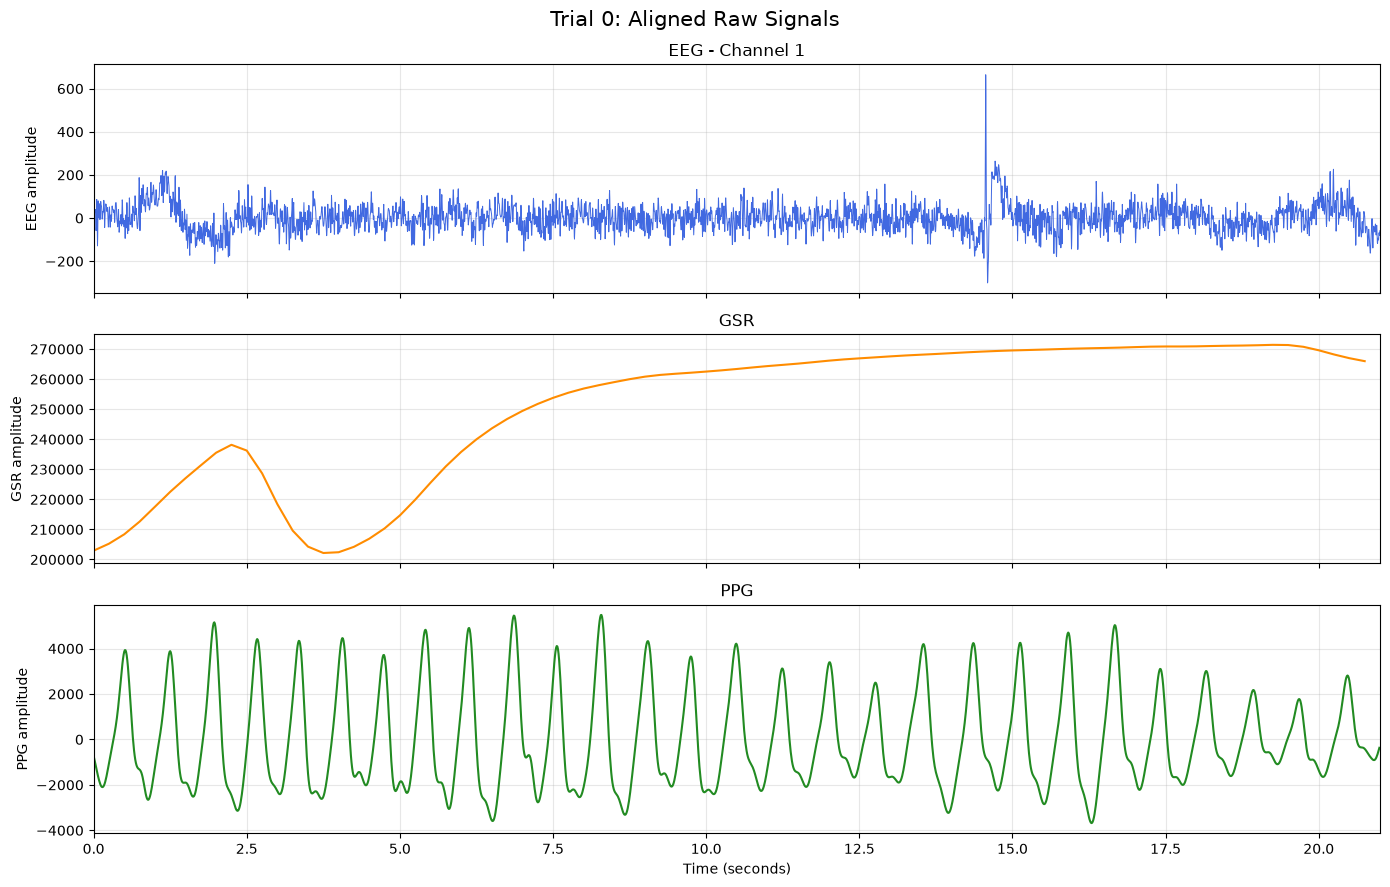

In [61]:
import numpy as np
import matplotlib.pyplot as plt

vid = 0
plot_seconds = 30

# Same duration alignment used during feature extraction
duration = int(min(
    eeg_trials[vid].shape[1] / fs_eeg,
    gsr_trials[vid].shape[1] / fs_gsr,
    ppg_trials[vid].shape[1] / fs_ppg
))

eeg_raw = eeg_trials[vid][:, -duration * fs_eeg:]
gsr_raw = gsr_trials[vid][:, -duration * fs_gsr:]
ppg_raw = ppg_trials[vid][:, -duration * fs_ppg:]

# Time axes
t_eeg = np.arange(eeg_raw.shape[1]) / fs_eeg
t_gsr = np.arange(gsr_raw.shape[1]) / fs_gsr
t_ppg = np.arange(ppg_raw.shape[1]) / fs_ppg

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

# EEG (channel 1)
axes[0].plot(t_eeg, eeg_raw[0], color="royalblue", linewidth=0.7)
axes[0].set_ylabel("EEG amplitude")
axes[0].set_title("EEG - Channel 1")
axes[0].grid(alpha=0.3)

# GSR
axes[1].plot(t_gsr, gsr_raw[0], color="darkorange")
axes[1].set_ylabel("GSR amplitude")
axes[1].set_title("GSR")
axes[1].grid(alpha=0.3)

# PPG
axes[2].plot(t_ppg, ppg_raw[0], color="forestgreen")
axes[2].set_ylabel("PPG amplitude")
axes[2].set_xlabel("Time (seconds)")
axes[2].set_title("PPG")
axes[2].grid(alpha=0.3)

axes[2].set_xlim(0, min(plot_seconds, duration))

plt.suptitle(f"Trial {vid}: Aligned Raw Signals", fontsize=15)
plt.tight_layout()
plt.show()

**2. Plot extracted EEG features**

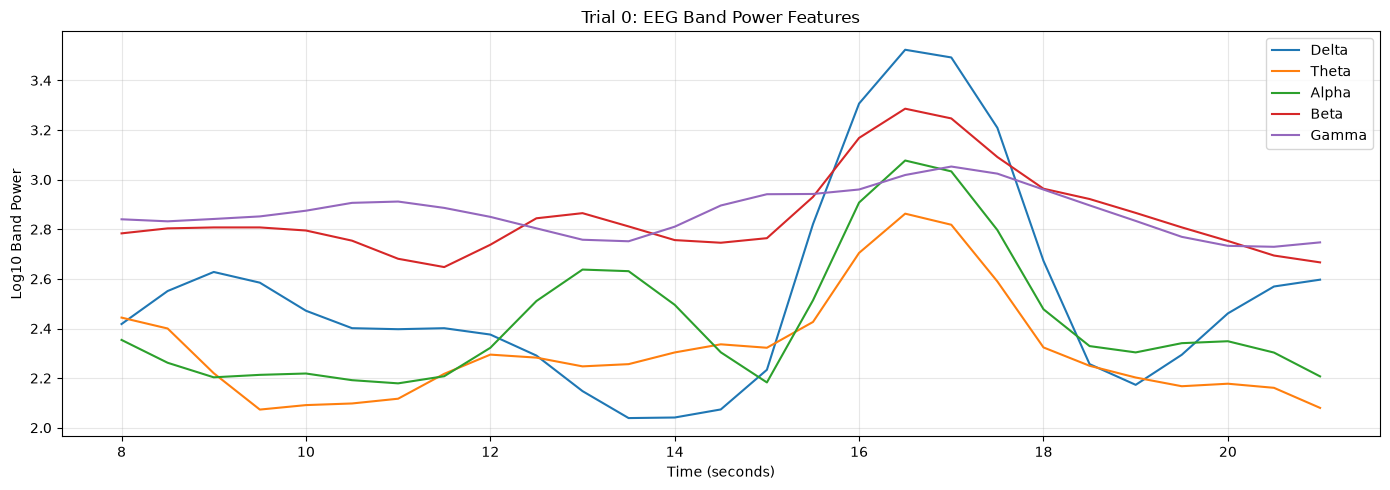

In [62]:
vid = 0

# Feature timestamps (window-end times)
times = feature_times[vid]

# Shape: (n_windows, 5 bands, 18 channels)
eeg_fea = eeg_features[vid].reshape(
    -1, len(freq_bands), 18
)

# Average across EEG channels
eeg_band_mean = eeg_fea.mean(axis=2)

plt.figure(figsize=(14, 5))

for i, band in enumerate(freq_bands):
    plt.plot(
        times,
        eeg_band_mean[:, i],
        label=band,
        linewidth=1.5
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Log10 Band Power")
plt.title(f"Trial {vid}: EEG Band Power Features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**3. Plot extracted GSR and PPG features**

- For GSR,extracted:
1. Mean
2. Standard deviation
3. Slope
- For PPG:
1. Pulse rate
2. Standard deviatio

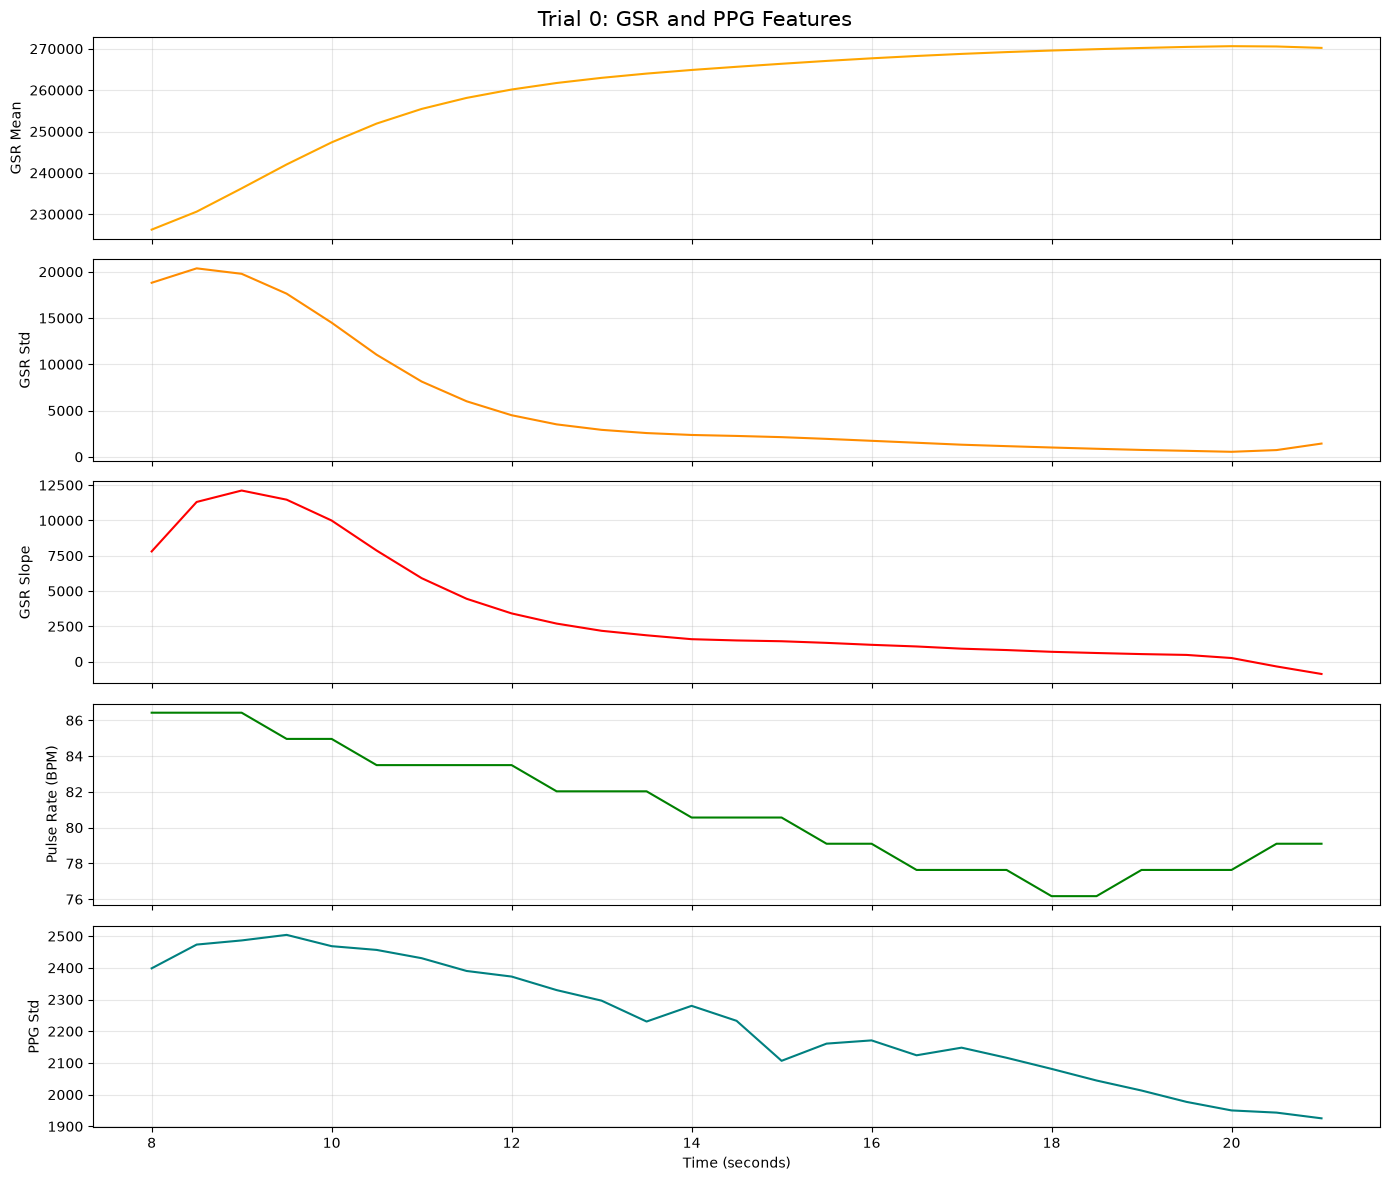

In [63]:
vid = 0

times = feature_times[vid]

gsr_fea = gsr_features[vid]
ppg_fea = ppg_features[vid]

fig, axes = plt.subplots(
    5, 1,
    figsize=(14, 12),
    sharex=True
)

# GSR Mean
axes[0].plot(times, gsr_fea[:, 0], color="orange")
axes[0].set_ylabel("GSR Mean")
axes[0].grid(alpha=0.3)

# GSR Standard Deviation
axes[1].plot(times, gsr_fea[:, 1], color="darkorange")
axes[1].set_ylabel("GSR Std")
axes[1].grid(alpha=0.3)

# GSR Slope
axes[2].plot(times, gsr_fea[:, 2], color="red")
axes[2].set_ylabel("GSR Slope")
axes[2].grid(alpha=0.3)

# PPG Pulse Rate
axes[3].plot(times, ppg_fea[:, 0], color="green")
axes[3].set_ylabel("Pulse Rate (BPM)")
axes[3].grid(alpha=0.3)

# PPG Standard Deviation
axes[4].plot(times, ppg_fea[:, 1], color="teal")
axes[4].set_ylabel("PPG Std")
axes[4].set_xlabel("Time (seconds)")
axes[4].grid(alpha=0.3)

plt.suptitle(
    f"Trial {vid}: GSR and PPG Features",
    fontsize=15
)

plt.tight_layout()
plt.show()